# Búsqueda híbrida: fusión convexa frente a LLM

Análisis ejecutado de los resultados guardados en Slurm. No repite inferencias. Incluye el estado real y los fallos; no sustituye archivos ausentes por métricas inventadas.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
p=Path.cwd()/'resultados'
display(json.loads((p/'verificacion_analisis.json').read_text()))

{'quality_complete': True,
 'metric_rows': 200,
 'performance_complete': True,
 'paired_bootstrap_rows': 3,
 'latency_observations': 2000,
 'analysis_job': '64080'}

## Calidad y diferencias pareadas

In [2]:
for name in ['calidad_resumen.csv','diferencias_pareadas.csv','cobertura_qrels.csv','diagnostico_scores.json']:
    f=p/name
    if f.exists():
        print(name)
        display(pd.read_csv(f) if f.suffix=='.csv' else json.loads(f.read_text()))

calidad_resumen.csv


,method,P3,nDCG3,MRR10
0,BM25,0.546667,0.460000,0.696722
1,LLM,0.666667,0.617952,0.844556
2,fusion,0.686667,0.640187,0.885667
3,semantic,0.613333,0.592775,0.874333


diferencias_pareadas.csv


,metric,queries,difference_LLM_minus_fusion,ci95_low,ci95_high,wins,ties,losses,bootstrap_replicates,seed
0,P3,50,-0.020000,-0.113333,0.073333,14,22,14,10000,42
1,nDCG3,50,-0.022235,-0.110876,0.062423,15,16,19,10000,42
2,MRR10,50,-0.041111,-0.131111,0.051667,7,33,10,10000,42


cobertura_qrels.csv


,qid,positive_in_subset,judged_in_subset
0,14,13,73
1,35,8,68
2,21,38,89
3,20,45,71
4,18,37,76
5,15,24,117
6,8,29,90
7,40,34,70
8,11,24,109
9,50,13,60


diagnostico_scores.json


{'pairs': 893,
 'invalid_scores': 0,
 'degraded_label_mass_fraction': 0.004479283314669653,
 'truncation_fraction': 0.004479283314669653,
 'score_zero_or_one_fraction': 0.0}

## Batch, concurrencia y latencia

In [3]:
for name in ['batches_resumen.csv','estabilidad_batches.csv','concurrencia_resumen.csv','latencia_resumen.csv']:
    f=p/name
    if f.exists():
        print(name)
        display(pd.read_csv(f))

batches_resumen.csv


,batch,median_pairs_per_second,median_seconds,successful_repeats
0,1,2.423642,73.030573,3
1,4,1.914242,92.464800,3
2,8,1.674903,105.677754,3


estabilidad_batches.csv


,batch,complete,max_absolute_score_difference,identical_top3,accepted
0,1,True,0.000000,True,True
1,4,True,0.000050,True,True
2,8,True,0.000044,True,True


concurrencia_resumen.csv


,concurrency,requests,errors,seconds,successful_requests_per_second
0,4,50,0,364.934823,0.137011
1,2,50,0,364.935834,0.137010
2,1,50,0,364.989103,0.136990


latencia_resumen.csv


,method,requests,successful,errors,p50_seconds,p95_seconds,p99_seconds,mean_seconds,p99_exploratory
0,LLM,1000,1000,0,7.230908,8.801827,9.479621,7.296164,False
1,fusion,1000,1000,0,0.022296,0.023027,0.023663,0.022351,False


## Figuras

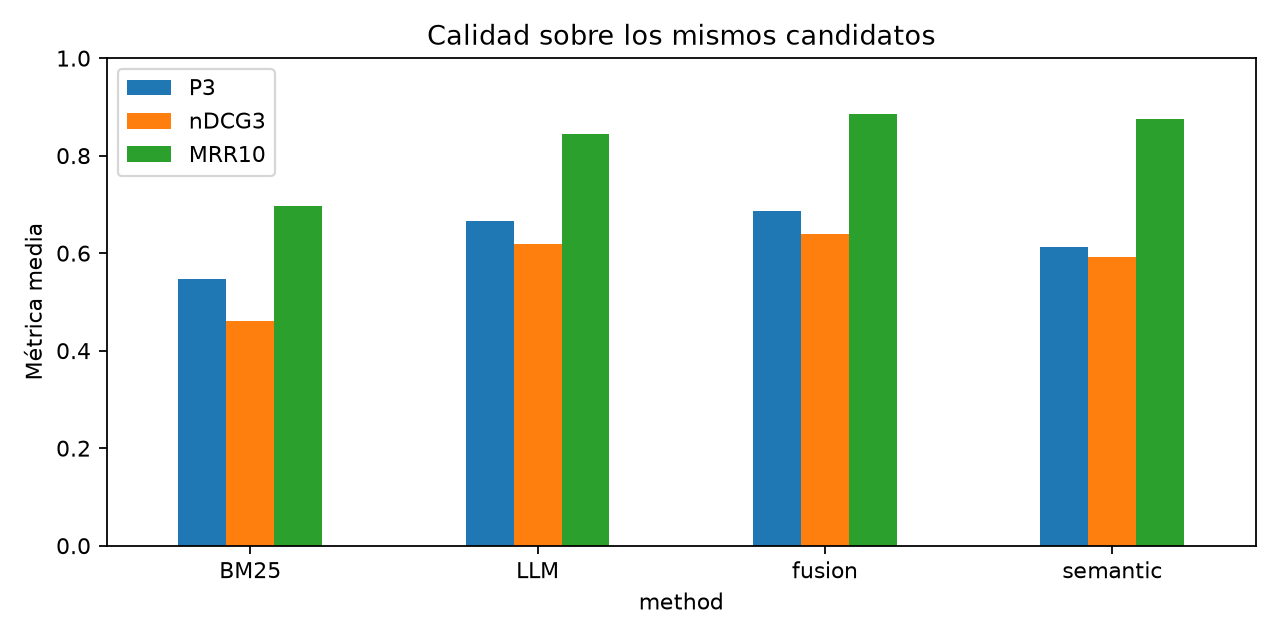

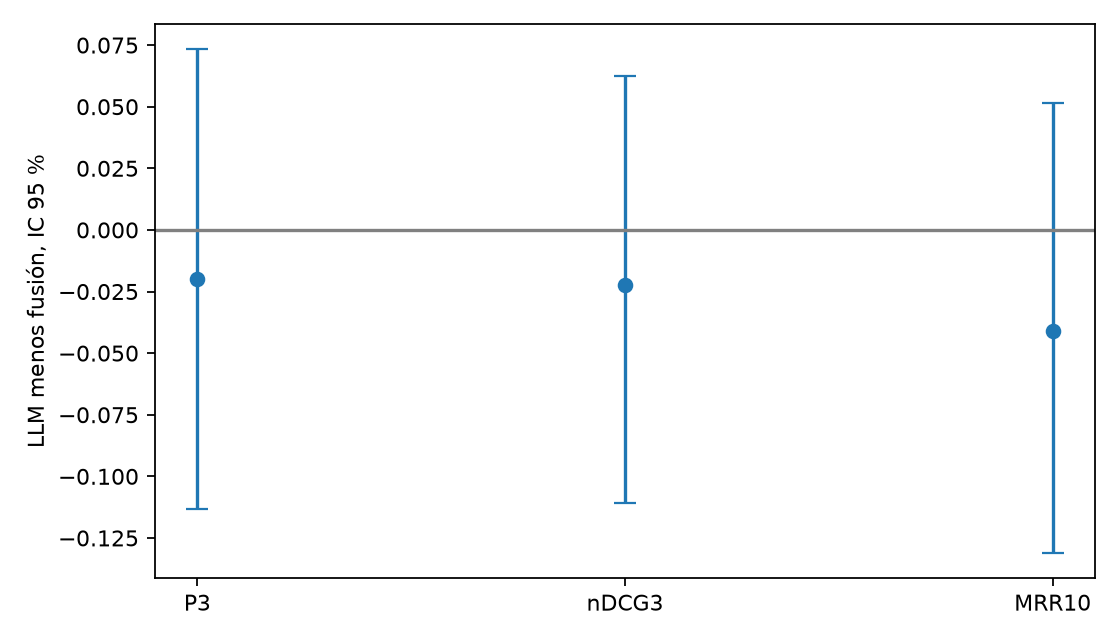

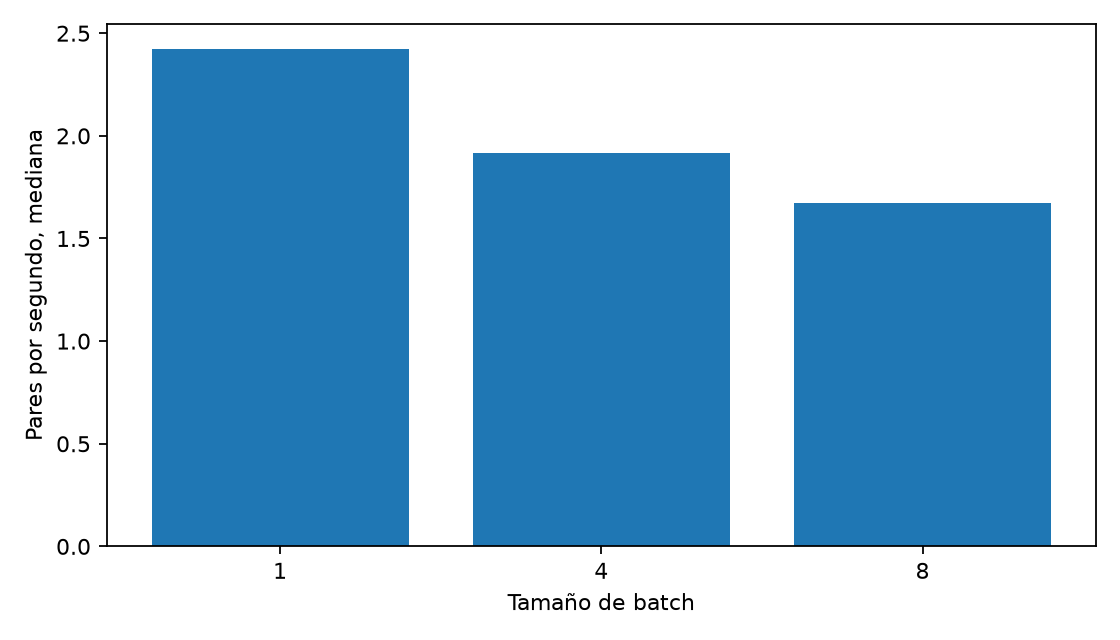

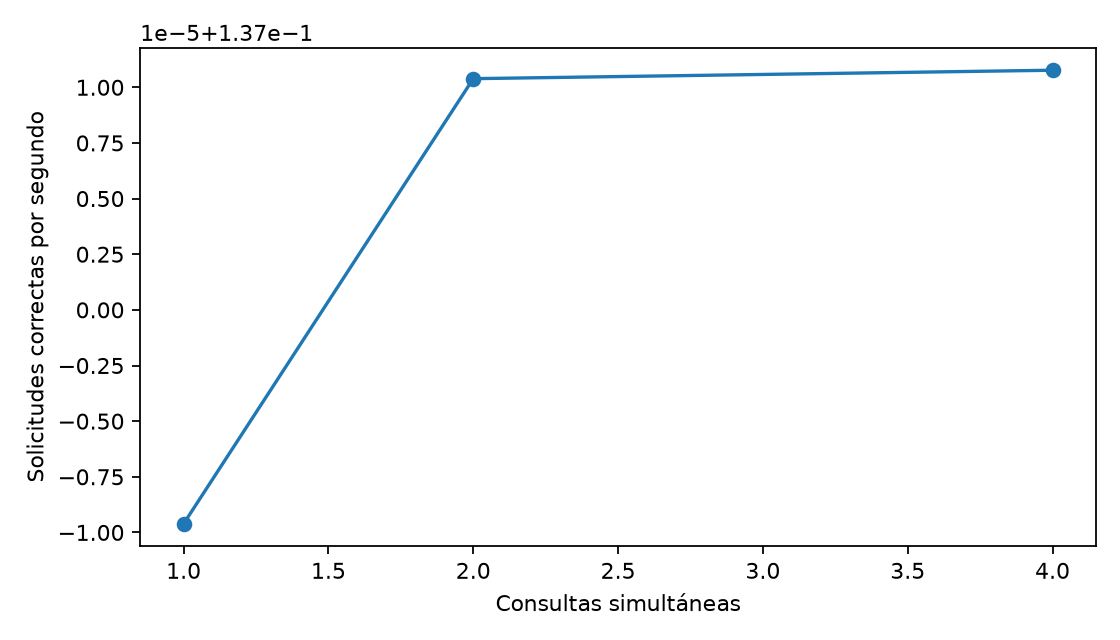

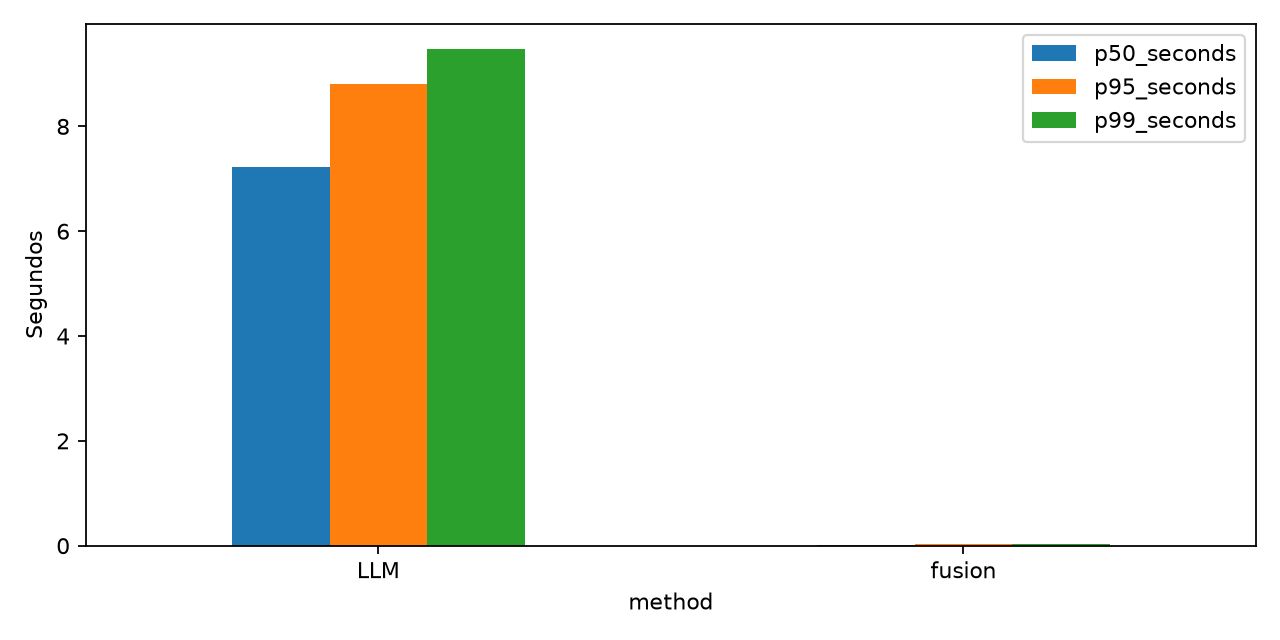

In [4]:
for f in sorted(p.glob('fig*.png')):
    display(Image(filename=str(f)))

## Interpretación y limitaciones

In [5]:
display(Markdown((p/'informe.md').read_text()))

# Comparación de fusión convexa y puntuación LLM

Análisis exploratorio de TREC-COVID sobre un corpus aleatorio de 10.000 documentos. Solo cambia la etapa final de ranking.

**Calidad completa:** True. Una tabla parcial no equivale a una evaluación final.

quality: job 64078, nodo ag001, GPU NVIDIA A100-PCIE-40GB MIG 3g.20gb, precisión LLM float32.

performance: job 64079, nodo ag001, GPU NVIDIA A100-PCIE-40GB MIG 3g.20gb, precisión LLM float32.

## Relevancia

| method   |       P3 |    nDCG3 |    MRR10 |
|:---------|---------:|---------:|---------:|
| BM25     | 0.546667 | 0.46     | 0.696722 |
| LLM      | 0.666667 | 0.617952 | 0.844556 |
| fusion   | 0.686667 | 0.640187 | 0.885667 |
| semantic | 0.613333 | 0.592775 | 0.874333 |

| metric   |   queries |   difference_LLM_minus_fusion |   ci95_low |   ci95_high |   wins |   ties |   losses |   bootstrap_replicates |   seed |
|:---------|----------:|------------------------------:|-----------:|------------:|-------:|-------:|---------:|-----------------------:|-------:|
| P3       |        50 |                    -0.02      |  -0.113333 |   0.0733333 |     14 |     22 |       14 |                  10000 |     42 |
| nDCG3    |        50 |                    -0.0222351 |  -0.110876 |   0.062423  |     15 |     16 |       19 |                  10000 |     42 |
| MRR10    |        50 |                    -0.0411111 |  -0.131111 |   0.0516667 |      7 |     33 |       10 |                  10000 |     42 |

Consultas con al menos un positivo juzgado en la muestra: 50/50. Las métricas principales conservan todas las consultas.

Diagnóstico de puntuación: `{"pairs": 893, "invalid_scores": 0, "degraded_label_mass_fraction": 0.004479283314669653, "truncation_fraction": 0.004479283314669653, "score_zero_or_one_fraction": 0.0}`. Una masa baja en las etiquetas limita la interpretación del score condicional.

## Batch y estabilidad

|   batch |   median_pairs_per_second |   median_seconds |   successful_repeats |
|--------:|--------------------------:|-----------------:|---------------------:|
|       1 |                   2.42364 |          73.0306 |                    3 |
|       4 |                   1.91424 |          92.4648 |                    3 |
|       8 |                   1.6749  |         105.678  |                    3 |

|   batch | complete   |   max_absolute_score_difference | identical_top3   | accepted   |
|--------:|:-----------|--------------------------------:|:-----------------|:-----------|
|       1 | True       |                     0           | True             | True       |
|       4 | True       |                     4.95017e-05 | True             | True       |
|       8 | True       |                     4.41968e-05 | True             | True       |

## Concurrencia

|   concurrency |   requests |   errors |   seconds |   successful_requests_per_second |
|--------------:|-----------:|---------:|----------:|---------------------------------:|
|             4 |         50 |        0 |   364.935 |                         0.137011 |
|             2 |         50 |        0 |   364.936 |                         0.13701  |
|             1 |         50 |        0 |   364.989 |                         0.13699  |

Carga cerrada con una instancia de modelo y acceso GPU serializado; incluye espera interna. No demuestra capacidad con llegadas abiertas ni un óptimo universal.

## Latencia completa

| method   |   requests |   successful |   errors |   p50_seconds |   p95_seconds |   p99_seconds |   mean_seconds | p99_exploratory   |
|:---------|-----------:|-------------:|---------:|--------------:|--------------:|--------------:|---------------:|:------------------|
| LLM      |       1000 |         1000 |        0 |      7.23091  |     8.80183   |     9.47962   |      7.29616   | False             |
| fusion   |       1000 |         1000 |        0 |      0.022296 |     0.0230266 |     0.0236634 |      0.0223509 | False             |

Los percentiles corresponden a solicitudes correctas; los errores se informan por separado. Consultas repetidas, modelos calientes y sin caché de respuestas. p99 es especialmente incierto con pocas observaciones.

Coste adicional medio en 1000 solicitudes pareadas: 7.2738 s.

## Recuperación

`{
  "passed": true,
  "interrupted_process_exit": 77,
  "committed_before_stop": 3,
  "expected": 40,
  "actual": 40,
  "duplicate_rows": 0,
  "missing_rows": 0,
  "scope": "real abrupt subprocess exit, committed score checkpoint and replay; stored reference scores, no model re-inference or machine failure"
}`

## Límites e interpretación

Los juicios son independientes del LLM y están incompletos. El score no es una probabilidad calibrada ni una verificación de verdad científica. El corpus es una muestra de 10.000 documentos, no el benchmark completo. TREC-COVID ya fue observado en trabajos anteriores: no se afirma una prueba ciega.

Los dos métodos comparten búsquedas y candidatos; el estudio atribuye diferencias a la puntuación final bajo esta configuración. No se agregan aquí los experimentos complementarios de los compañeros, que deberán identificarse por separado.

La conclusión de valor debe combinar la diferencia de relevancia y su incertidumbre con el coste de latencia. Una mejora de calidad no se presupone; no se cambia el prompt ni se descartan consultas para obtenerla.
